# Блокнот 05: Прогнозування початку тривог та змагання моделей (Етап 2)

**Постановка задачі:**
> *Прогноз формується у спокійні години (`is_active_T == 0`) для кожної з 24 областей України. Цільова змінна $y_T = 1$, якщо нова тривога починається у піввідкритому інтервалі $[T, T + 1\text{h})$ (`k_onset = s_sec // 3600`).*

**Особливості конвеєра даних та захисту від витоку:**
1. Після серпня 2025 року тривоги області агреговано з районних та громадських записів (`oblast`, `raion`, `hromada`) шляхом об'єднання перетинних інтервалів `[started_at, finished_at]`.
2. Кластери для ML (`low_activity`, `medium_activity`, `high_activity`) навчені виключно на вибірці Train до `2024-04-30 23:59:59 UTC` (`reports/clusters_train_only.csv`).
3. Довірчі інтервали розраховано методом **Block Bootstrap за календарними добами** (`n_bootstraps = 500`).

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import Image, display

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
print('Бібліотеки успішно завантажено.')

Бібліотеки успішно завантажено.


## 1. Бейзлайни на вибірці Validation (2024–2025)

Оцінюються три бейзлайни:
* **Baseline 1: True Naive Persistence** — індикатор старту тривоги у попередній годині $[T-1\text{h}, T)$ на повній годинній сітці.
* **Baseline 2: Historical Lookup Table** — емпірична ймовірність старту `P(Onset | day_of_week, hour_kyiv, cluster_id)`, розрахована на Train.
* **Baseline 3: Adaptive 14-day Rolling** — ковзна частота стартів тривог у конкретній області за попередні 14 діб (336 годин до $T$, `closed='left'`).

Бенчмарк бейзлайнів на вибірці Validation:


,model,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686


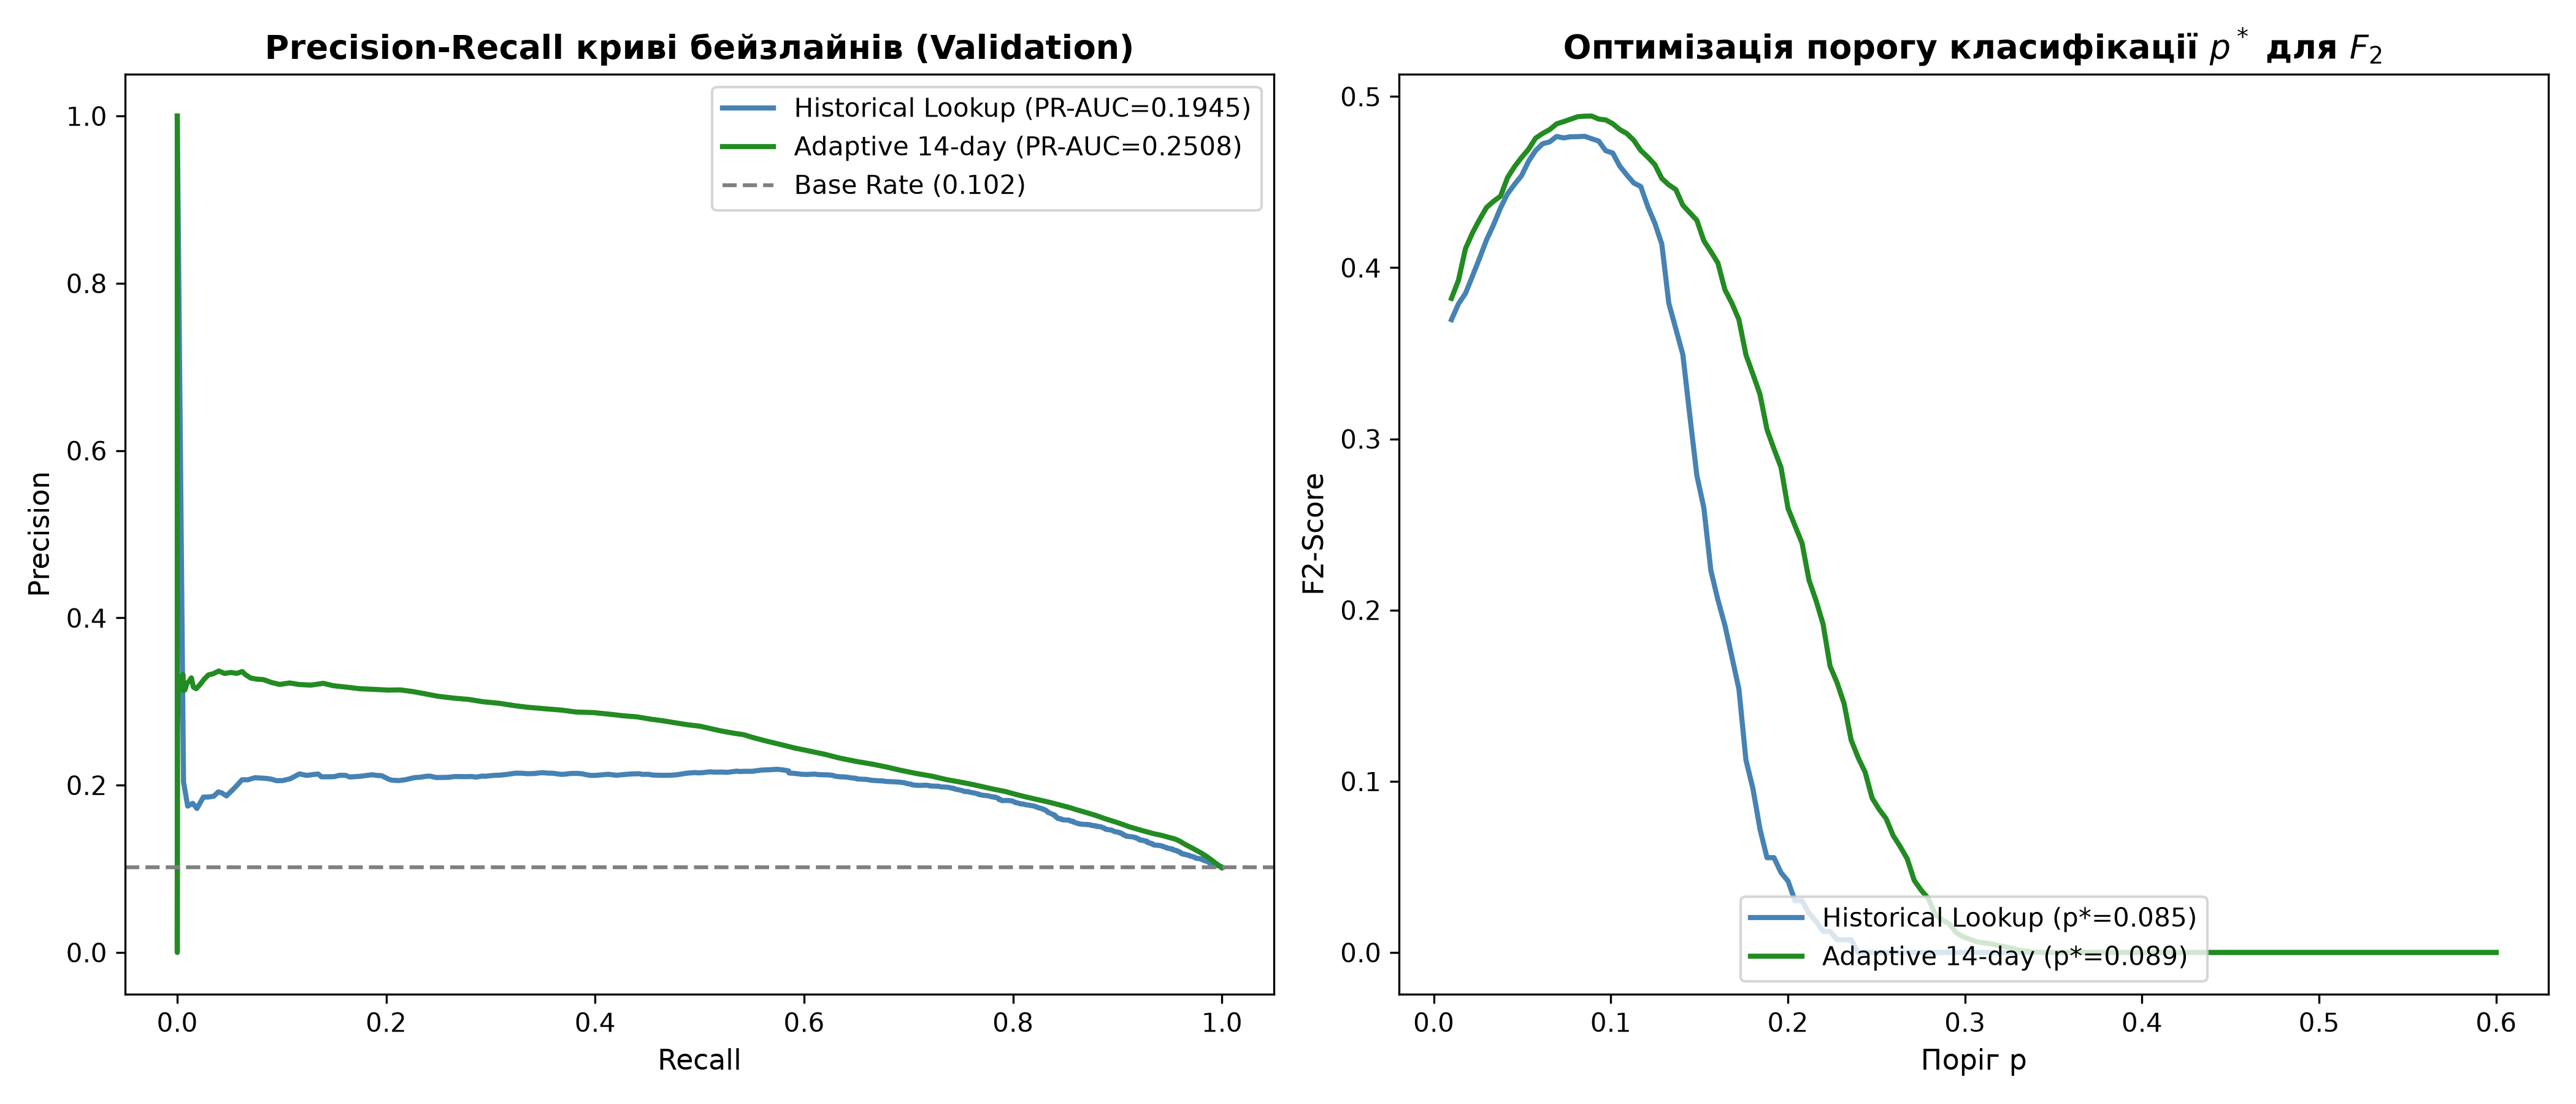

In [2]:
baselines_df = pd.read_csv('../reports/baselines_benchmark.csv')
print('Бенчмарк бейзлайнів на вибірці Validation:')
display(baselines_df)
display(Image('../reports/figures/07_baselines_performance.png'))

## 2. Навчання моделей та Ablation Study на Validation

Порівнюються дві родини моделей (Logistic Regression та LightGBM) на двох наборах ознак:
* **Підмножина A (No Spatial):** календарні цикли (`hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`, `month`), історичне навантаження (`burden_last_6h`, `burden_last_24h`) та Train-кластери (`low_activity`, `medium_activity`, `high_activity`).
* **Підмножина B (With Spatial):** Підмножина A + поточна активність сусідніх областей на момент $T$ (`neighbors_active_count`, `neighbor_any_active`, `neighbor_active_ratio`).

Підсумкова таблиця на Validation (підбір оптимальних порогів p* за максимумом F2):


,model,feature_set,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686
3,LogReg (No Spatial),A (Time & Lags),0.520805,0.191419,0.775256,0.481523,0.266656,0.235025
4,LogReg (With Spatial),"B (Time, Lags & Neighbors)",0.572282,0.215941,0.758763,0.504916,0.288191,0.245719
5,LightGBM (No Spatial),A (Time & Lags),0.093154,0.205969,0.741030,0.487663,0.268010,0.082417
6,LightGBM (With Spatial),"B (Time, Lags & Neighbors)",0.105034,0.212871,0.825819,0.524035,0.296142,0.079958


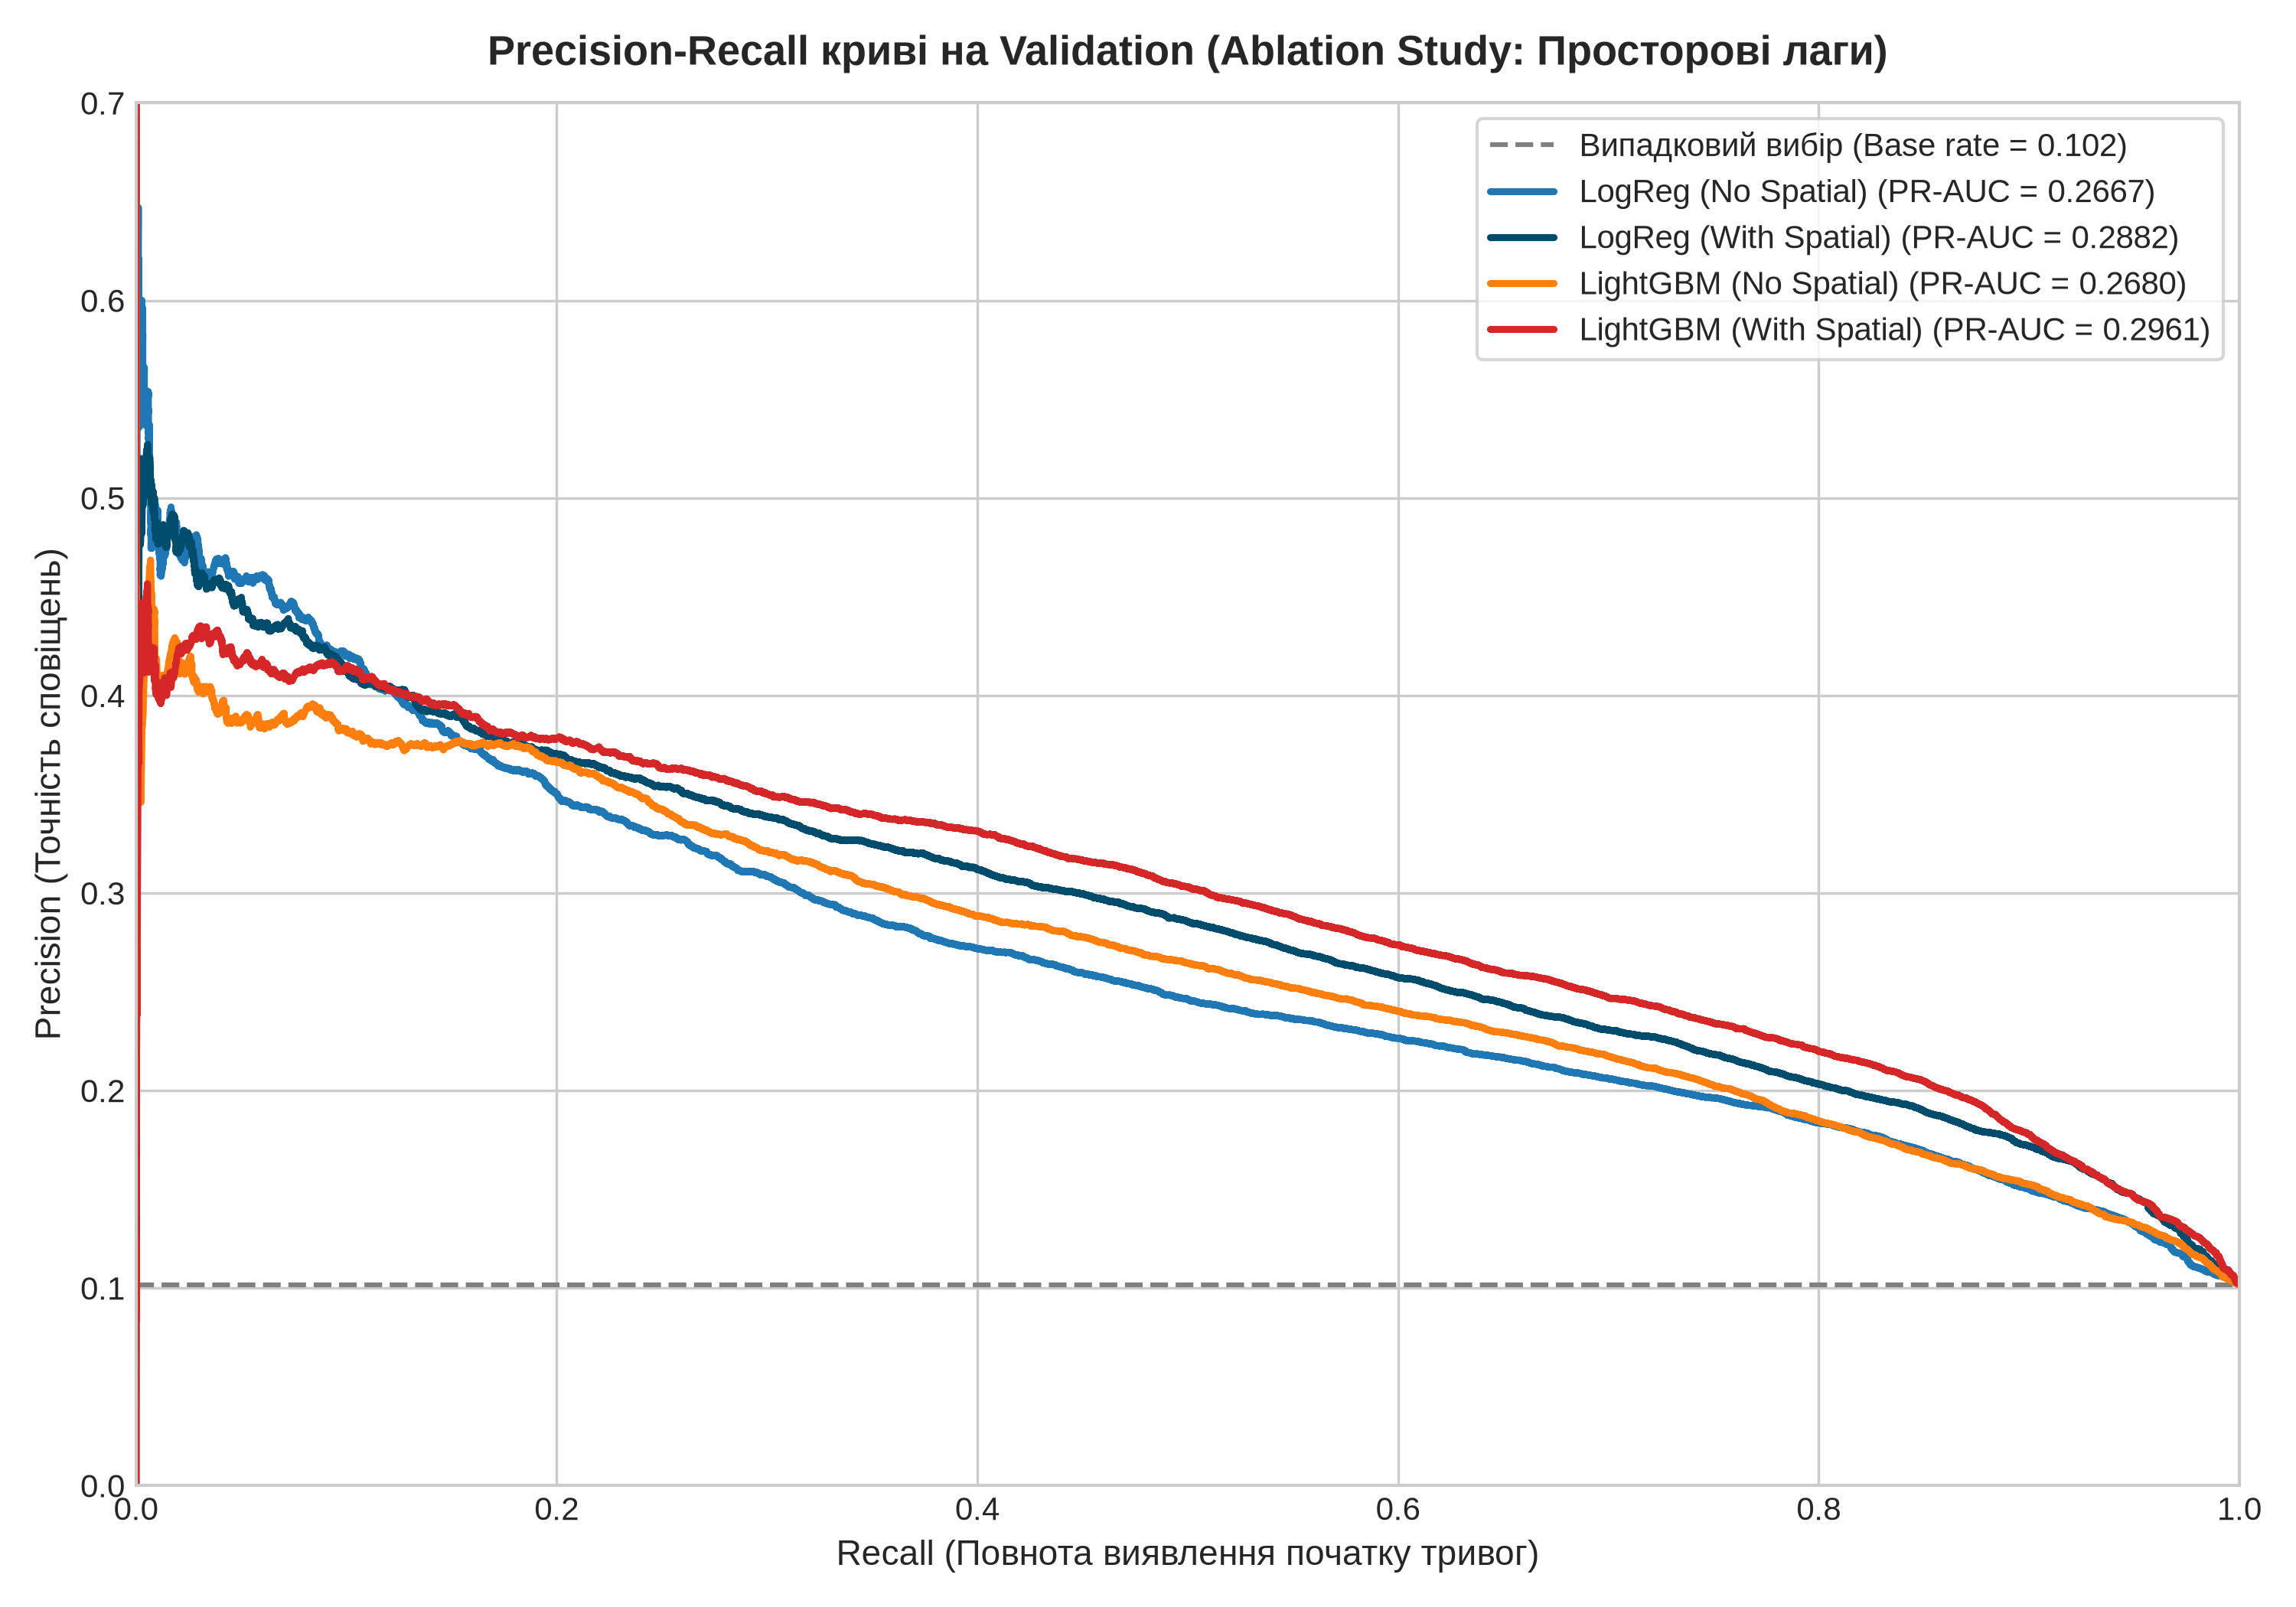

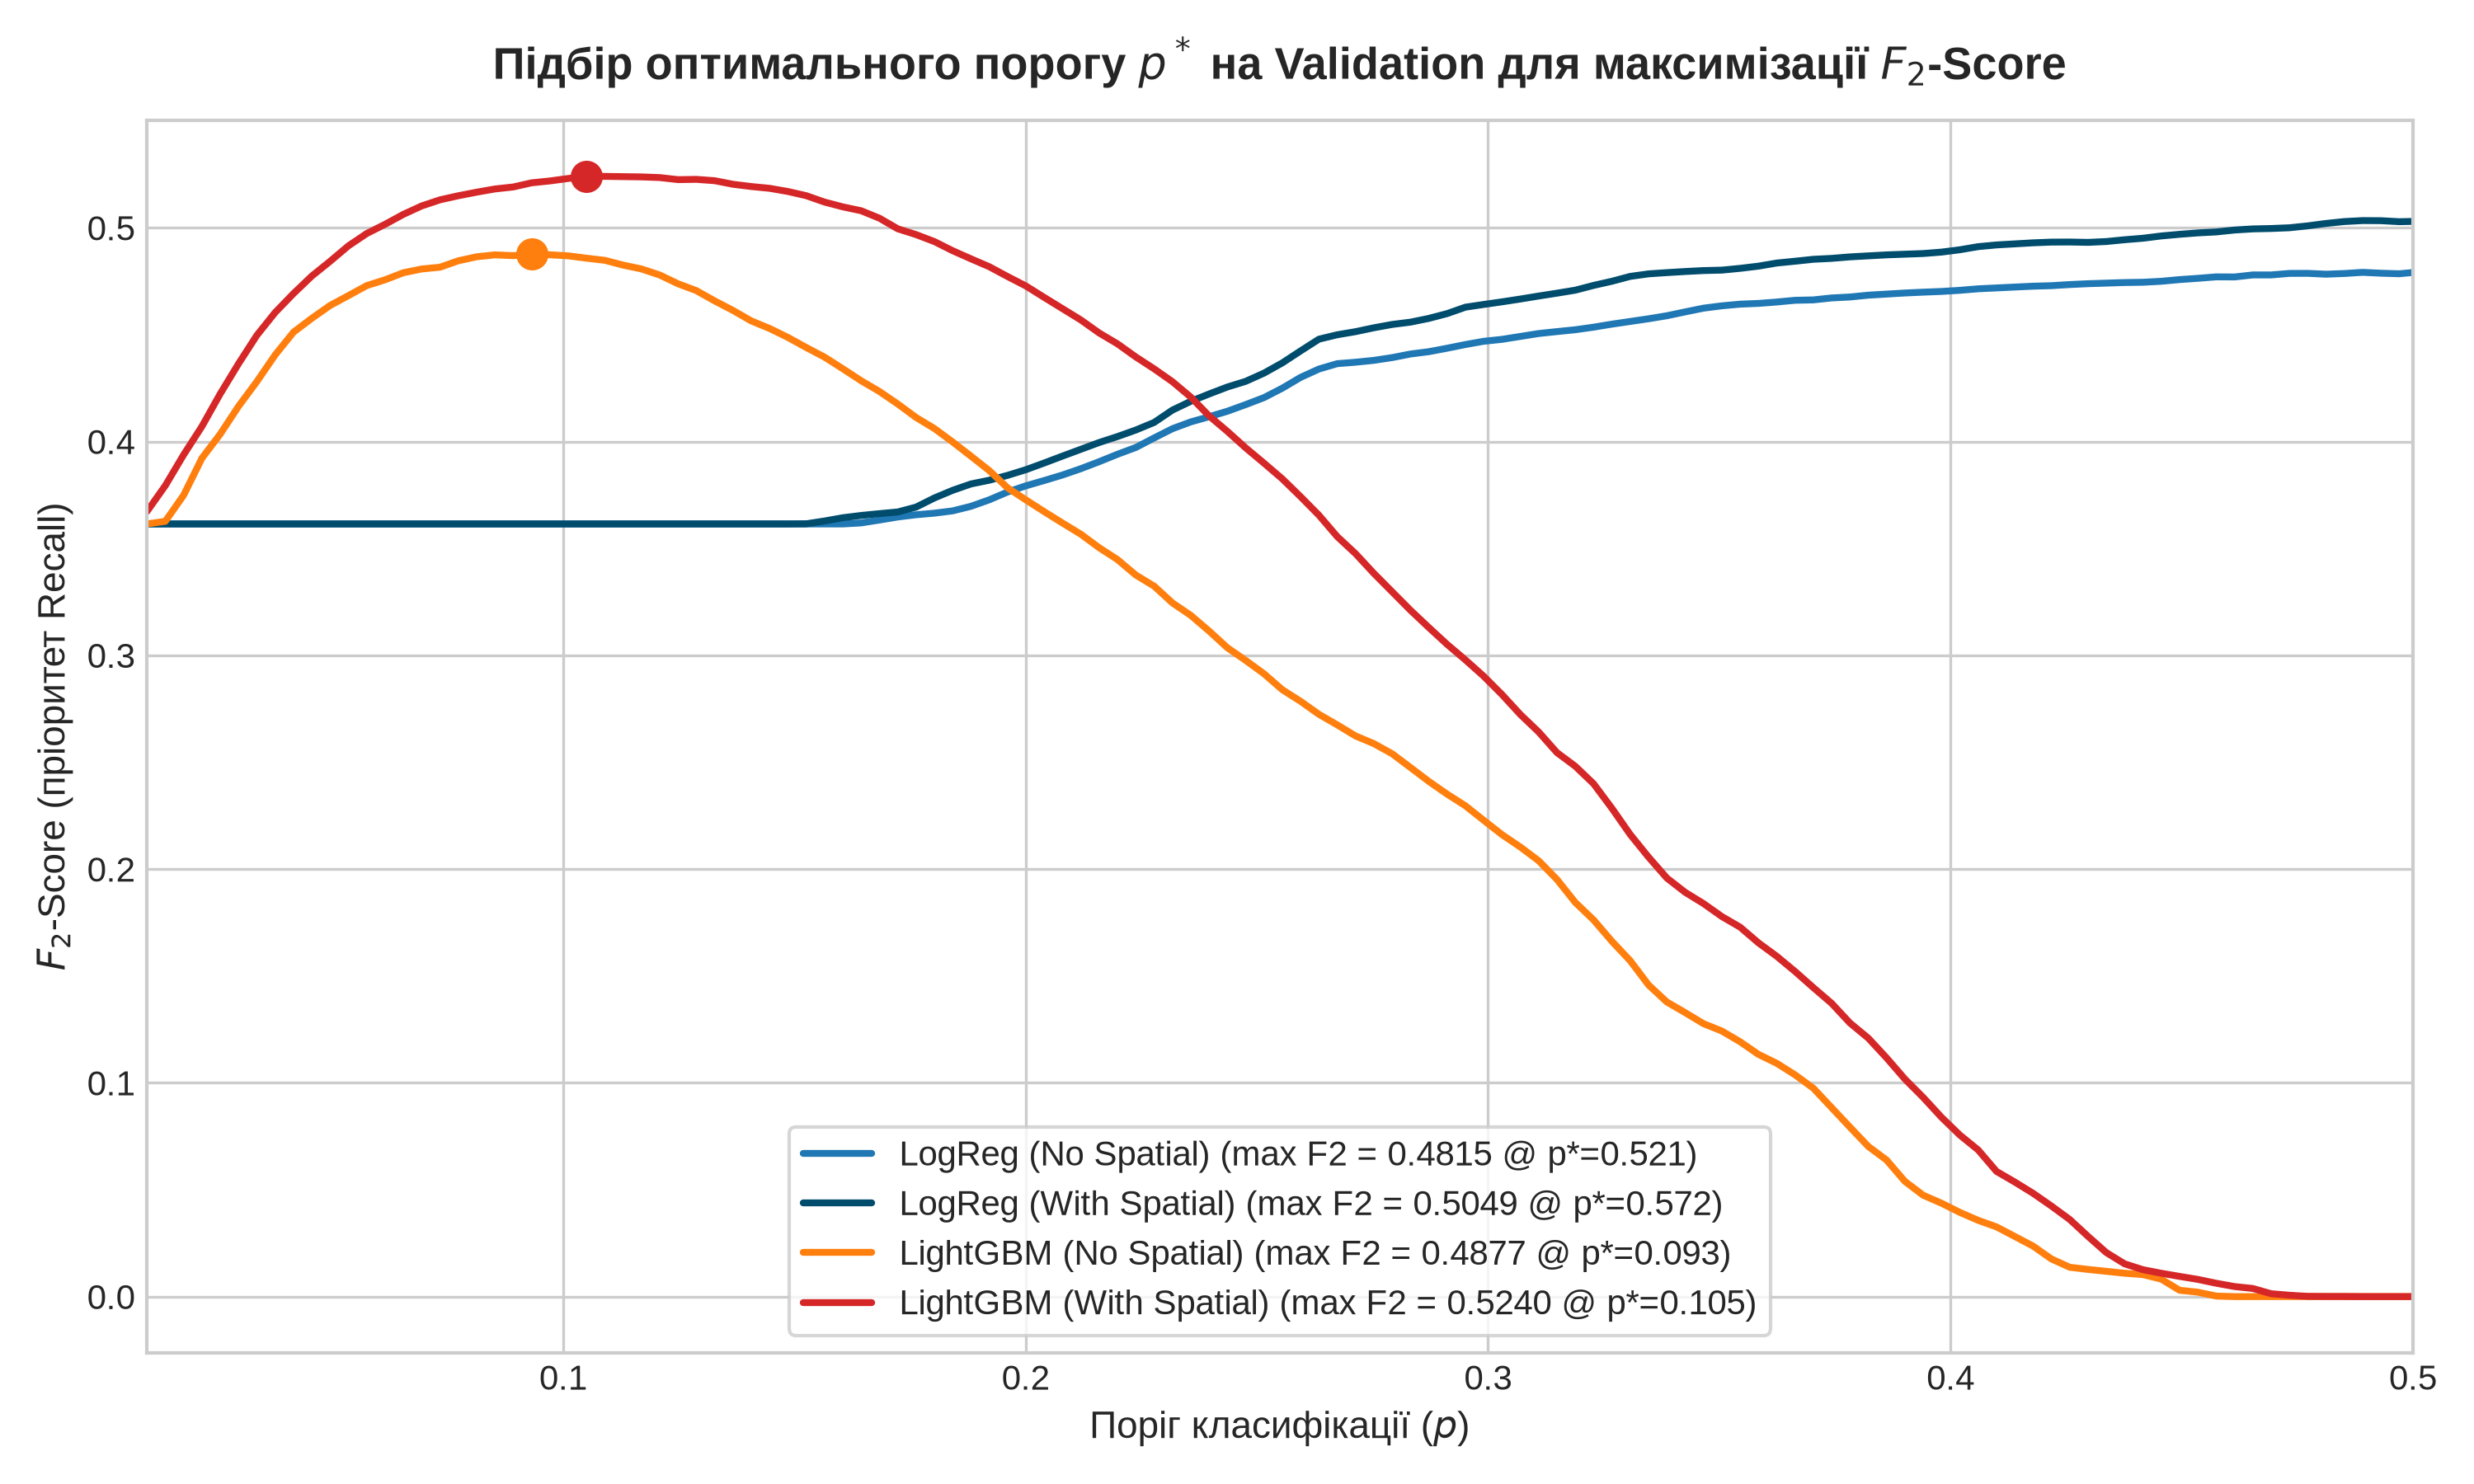

In [3]:
val_benchmark = pd.read_csv('../reports/ml_validation_benchmark.csv')
print('Підсумкова таблиця на Validation (підбір оптимальних порогів p* за максимумом F2):')
display(val_benchmark)
display(Image('../reports/figures/08_ml_pr_curves_validation.png'))
display(Image('../reports/figures/09_threshold_tuning_f2.png'))

## 3. Фінальна оцінка на Test (червень 2025 – вересень 2026) та останніх 60 днях

* На вибірці Test (197,083 спокійних годин, 464 календарні доби, 20,250 стартів тривог, базова частка **10.27%**) застосовано заморожені пороги $p^*$ з Validation.
* Для коректного порівняння наведено метрику `prec_at_adapt_recall` — точність кожної моделі при фіксованій повноті (Recall = 78.23%), рівній повноті найкращого адаптивного бейзлайну.
* Окремо збережено оцінку за **останні 60 днів** (09.07.2026 – 07.09.2026, 23,646 спокійних годин, 2,992 старти, базова частка **12.65%**) у `reports/ml_recent_60d_benchmark.csv`.

In [4]:
test_benchmark = pd.read_csv('../reports/ml_models_benchmark.csv')
print('Фінальний бенчмарк на повному Test (2025–2026, Day-Block Bootstrap N=500):')
display(test_benchmark)

recent_benchmark = pd.read_csv('../reports/ml_recent_60d_benchmark.csv')
print('\nБенчмарк на останніх 60 днях (липень – вересень 2026, Day-Block Bootstrap N=500):')
display(recent_benchmark)

with open('../reports/test_evaluation_details.json', 'r', encoding='utf-8') as f:
    details = json.load(f)
print('\nПарні різниці (Day-Block Bootstrap N=500):')
for k, v in details['paired_day_bootstrap_500'].items():
    print(f"  {k}: mean={v['mean']:+.4f}, 95% CI=[{v['ci_low']:+.4f}, {v['ci_high']:+.4f}]")

Фінальний бенчмарк на повному Test (2025–2026, Day-Block Bootstrap N=500):


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.290853,0.089037,0.103384,"[0.096, 0.111]",NaN,-,0.115905,NaN,NaN,-80.491508,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.227355,0.722519,0.503292,"[0.495, 0.511]",0.220406,"[0.212, 0.228]",0.086782,0.211073,0.697383,-5.029333,-27.289315
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.231394,0.782272,0.529945,"[0.520, 0.538]",0.303127,"[0.292, 0.315]",0.081774,0.231394,0.782272,0.000000,0.000000
3,LogReg (No Spatial),A (Time & Lags),0.520805,0.236557,0.774914,0.532528,"[0.524, 0.541]",0.388101,"[0.377, 0.399]",0.200706,0.233878,0.787062,0.487456,28.032428
4,LogReg (With Spatial),"B (Time, Lags & Neighbors)",0.572282,0.243362,0.804247,0.550497,"[0.542, 0.559]",0.390327,"[0.380, 0.400]",0.233705,0.251428,0.832346,3.878118,28.766730
5,LightGBM (No Spatial),A (Time & Lags),0.093154,0.254242,0.745778,0.537821,"[0.529, 0.546]",0.348187,"[0.337, 0.359]",0.078449,0.235330,0.788938,1.486164,14.864820
6,LightGBM (With Spatial),"B (Time, Lags & Neighbors)",0.105034,0.232395,0.863901,0.559711,"[0.551, 0.568]",0.374132,"[0.363, 0.386]",0.076120,0.268055,0.866025,5.616929,23.424068



Бенчмарк на останніх 60 днях (липень – вересень 2026, Day-Block Bootstrap N=500):


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.391667,0.141377,0.162094,"[0.145, 0.181]",NaN,-,0.136429,NaN,NaN,-74.791536,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.331462,0.730281,0.588631,"[0.564, 0.613]",0.325750,"[0.295, 0.357]",0.103754,0.218934,0.804144,-8.457358,-11.528568
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.298521,0.903743,0.643013,"[0.620, 0.664]",0.368198,"[0.333, 0.406]",0.091070,0.298521,0.903743,0.000000,0.000000
3,LogReg (No Spatial),A (Time & Lags),0.520805,0.356164,0.825535,0.653335,"[0.635, 0.674]",0.505829,"[0.480, 0.531]",0.169332,0.293753,0.898061,1.605260,37.379610
4,LogReg (With Spatial),"B (Time, Lags & Neighbors)",0.572282,0.330071,0.856618,0.649420,"[0.625, 0.674]",0.478765,"[0.444, 0.510]",0.206368,0.301988,0.912433,0.996300,30.029449
5,LightGBM (No Spatial),A (Time & Lags),0.093154,0.369644,0.813168,0.655795,"[0.639, 0.674]",0.450056,"[0.423, 0.477]",0.088450,0.293798,0.896056,1.987787,22.232253
6,LightGBM (With Spatial),"B (Time, Lags & Neighbors)",0.105034,0.296819,0.907420,0.642908,"[0.615, 0.669]",0.454075,"[0.424, 0.481]",0.085324,0.301651,0.905414,-0.016411,23.323684



Парні різниці (Day-Block Bootstrap N=500):
  lgb_spatial_minus_nospatial_prauc: mean=+0.0259, 95% CI=[+0.0226, +0.0293]
  lr_spatial_minus_nospatial_prauc: mean=+0.0024, 95% CI=[-0.0017, +0.0065]
  lgb_spatial_minus_adaptive_prauc: mean=+0.0711, 95% CI=[+0.0613, +0.0812]
  lgb_spatial_minus_adaptive_f2: mean=+0.0296, 95% CI=[+0.0247, +0.0353]


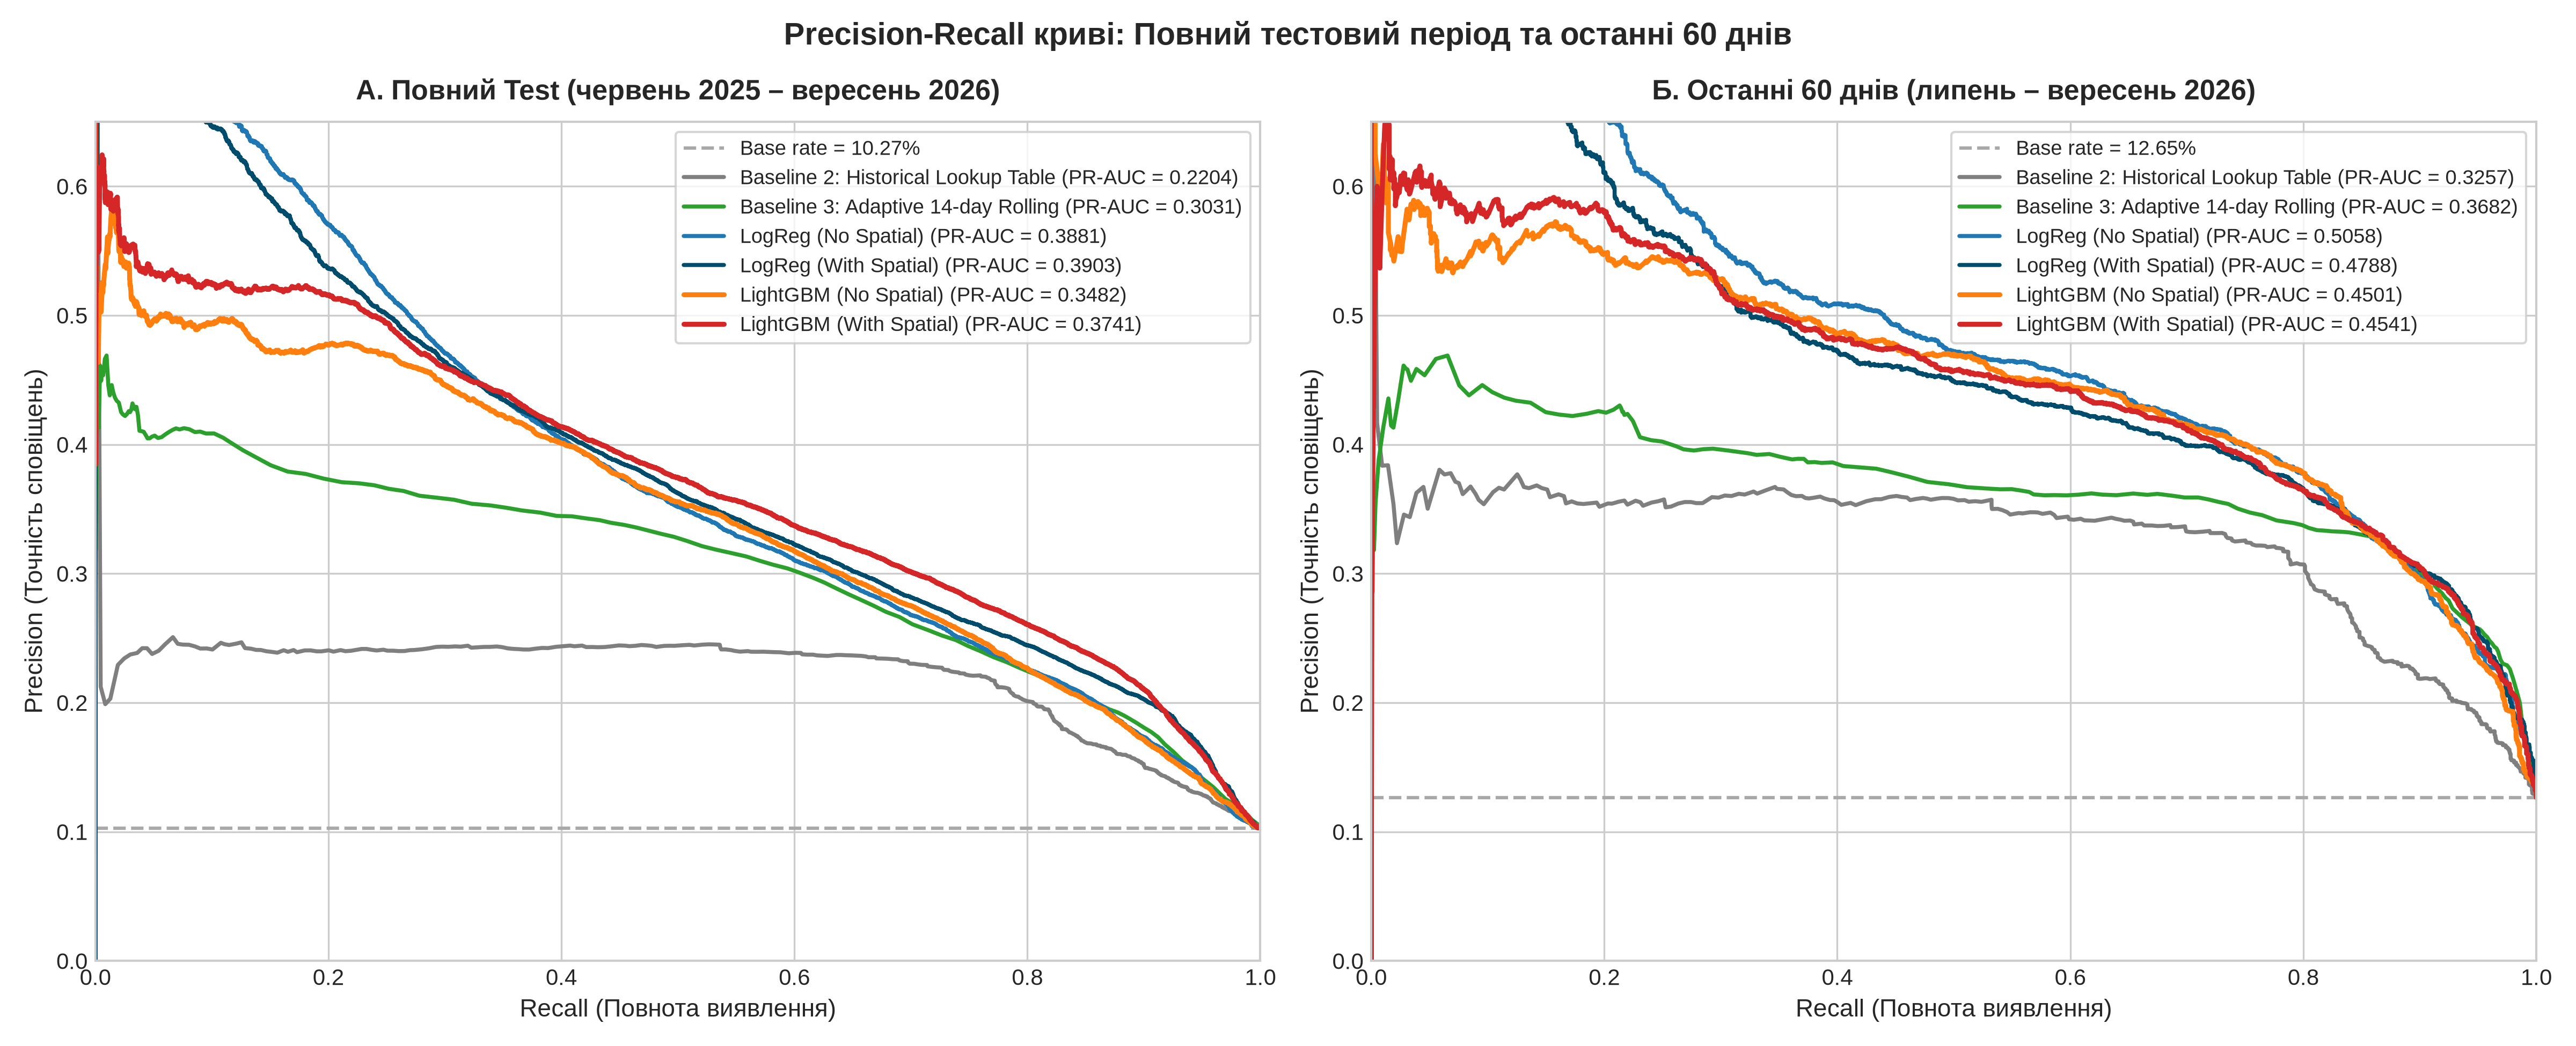

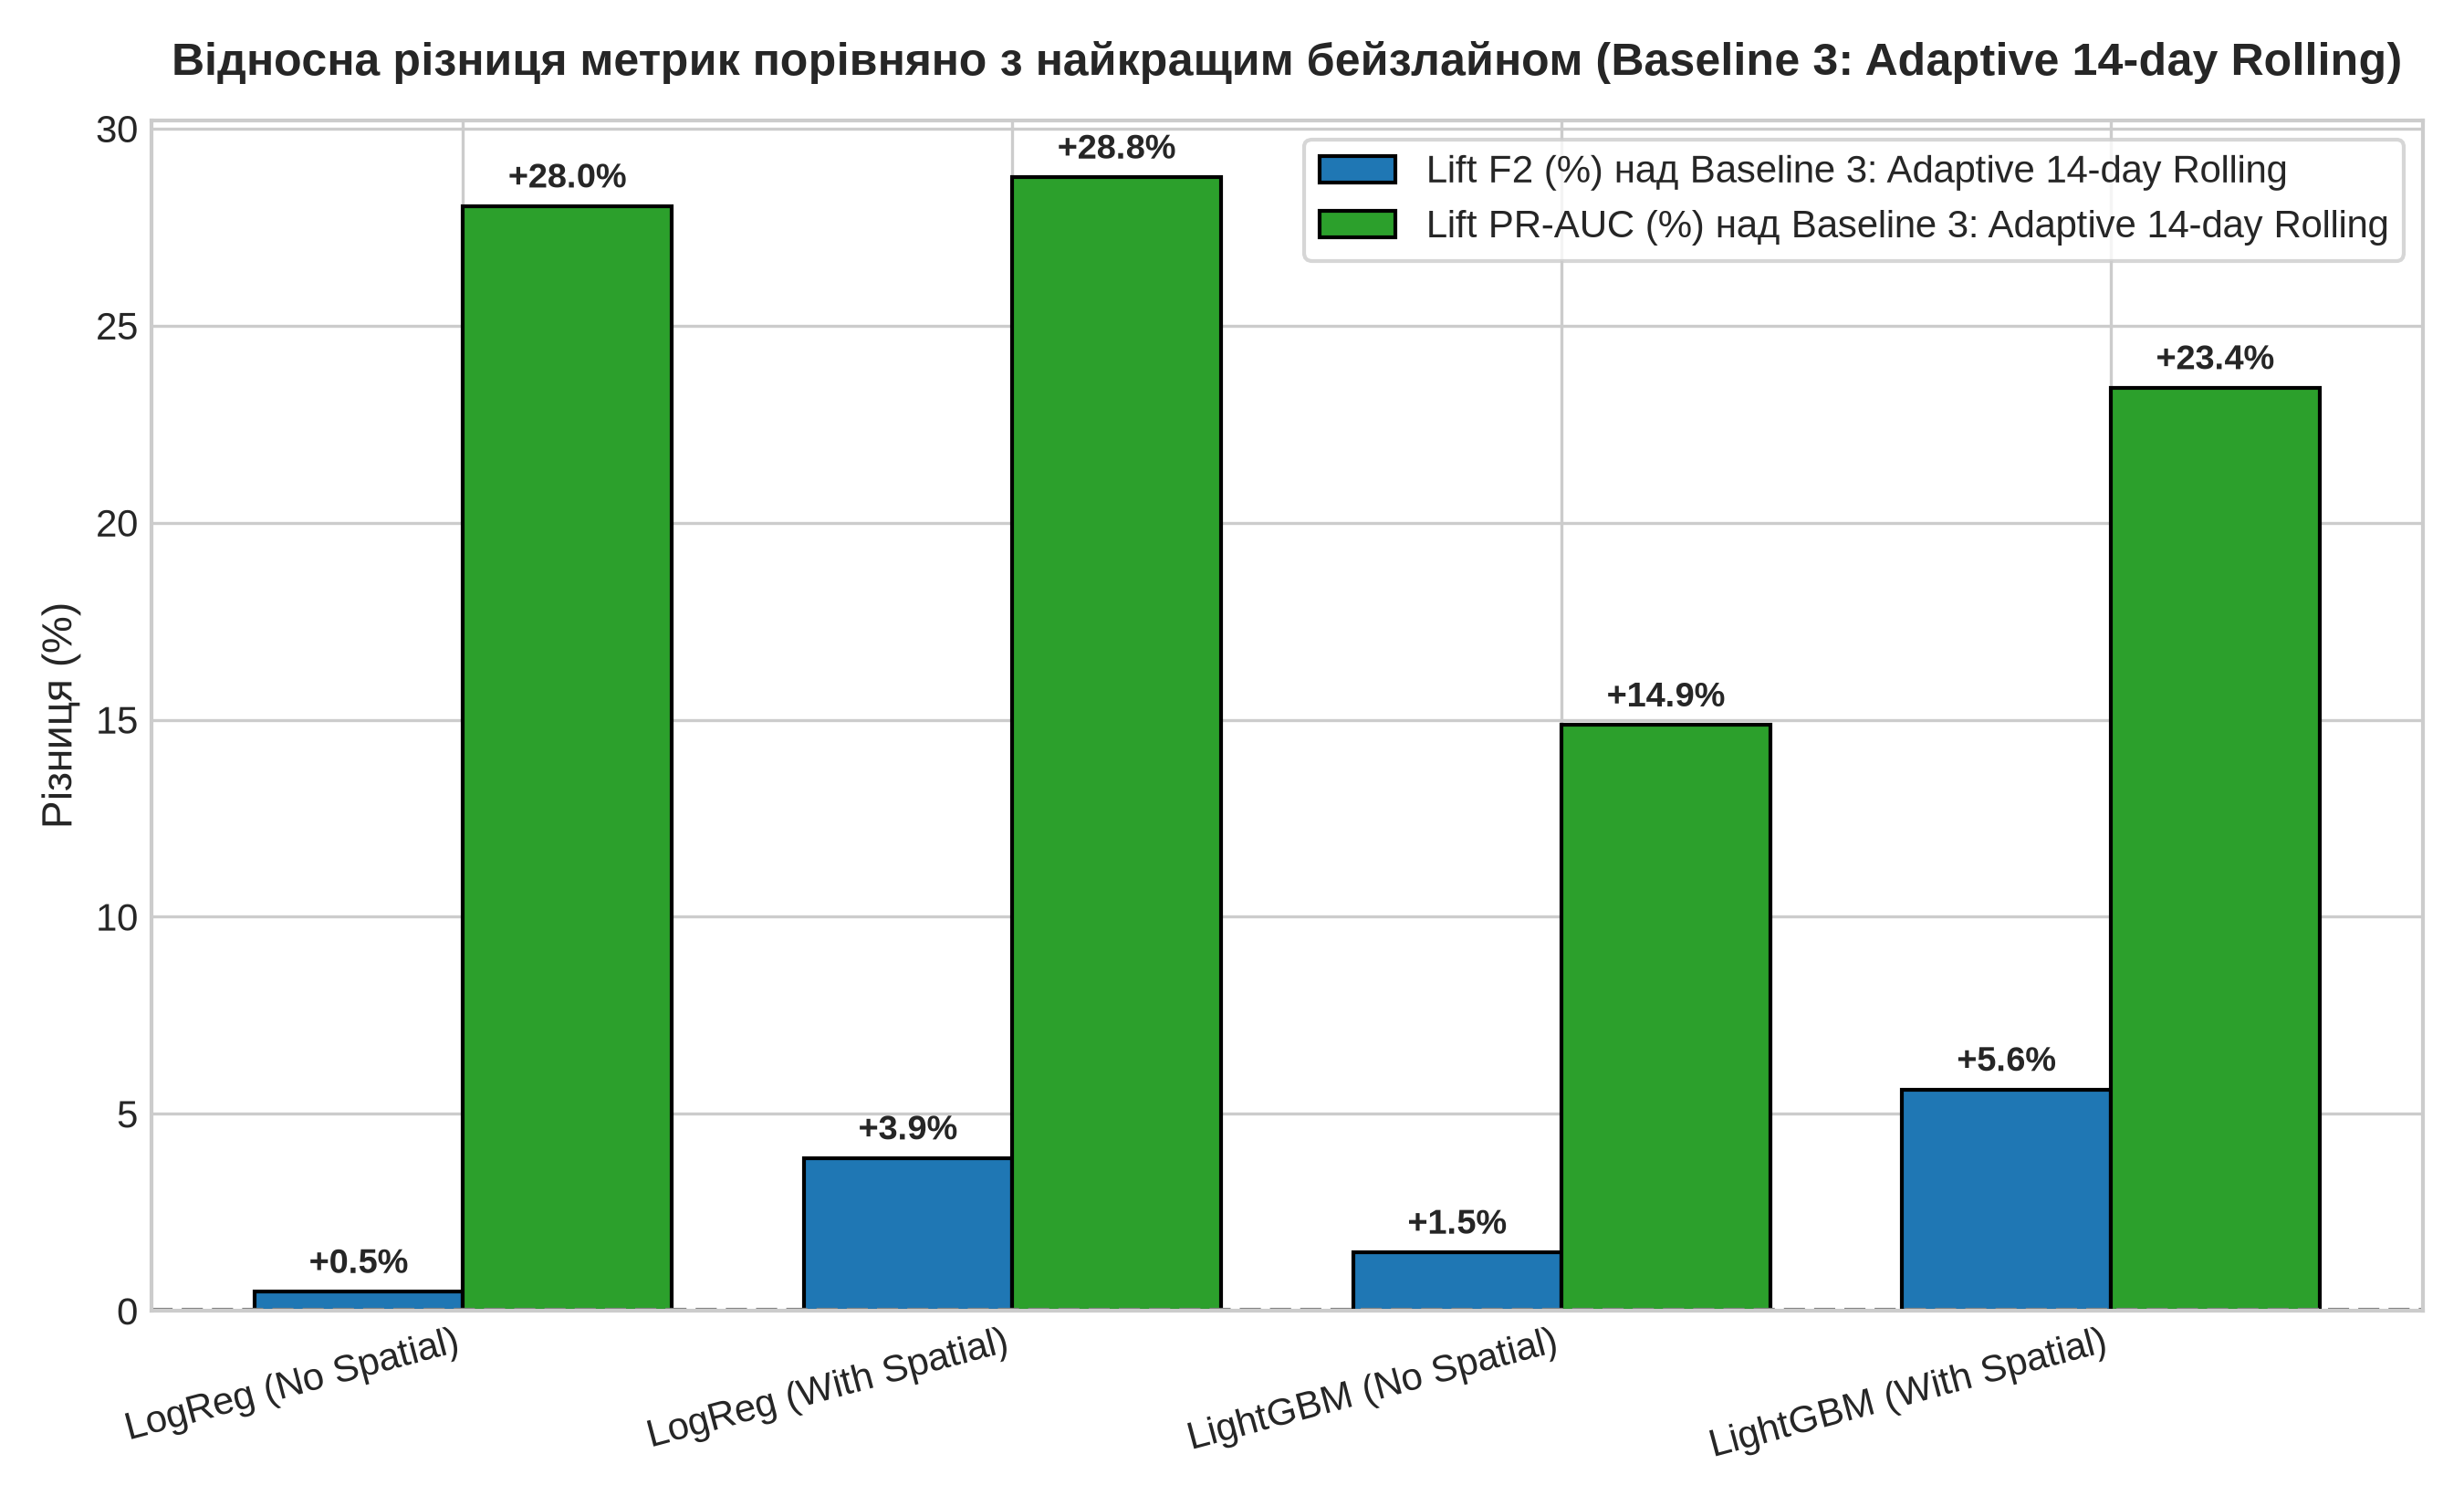

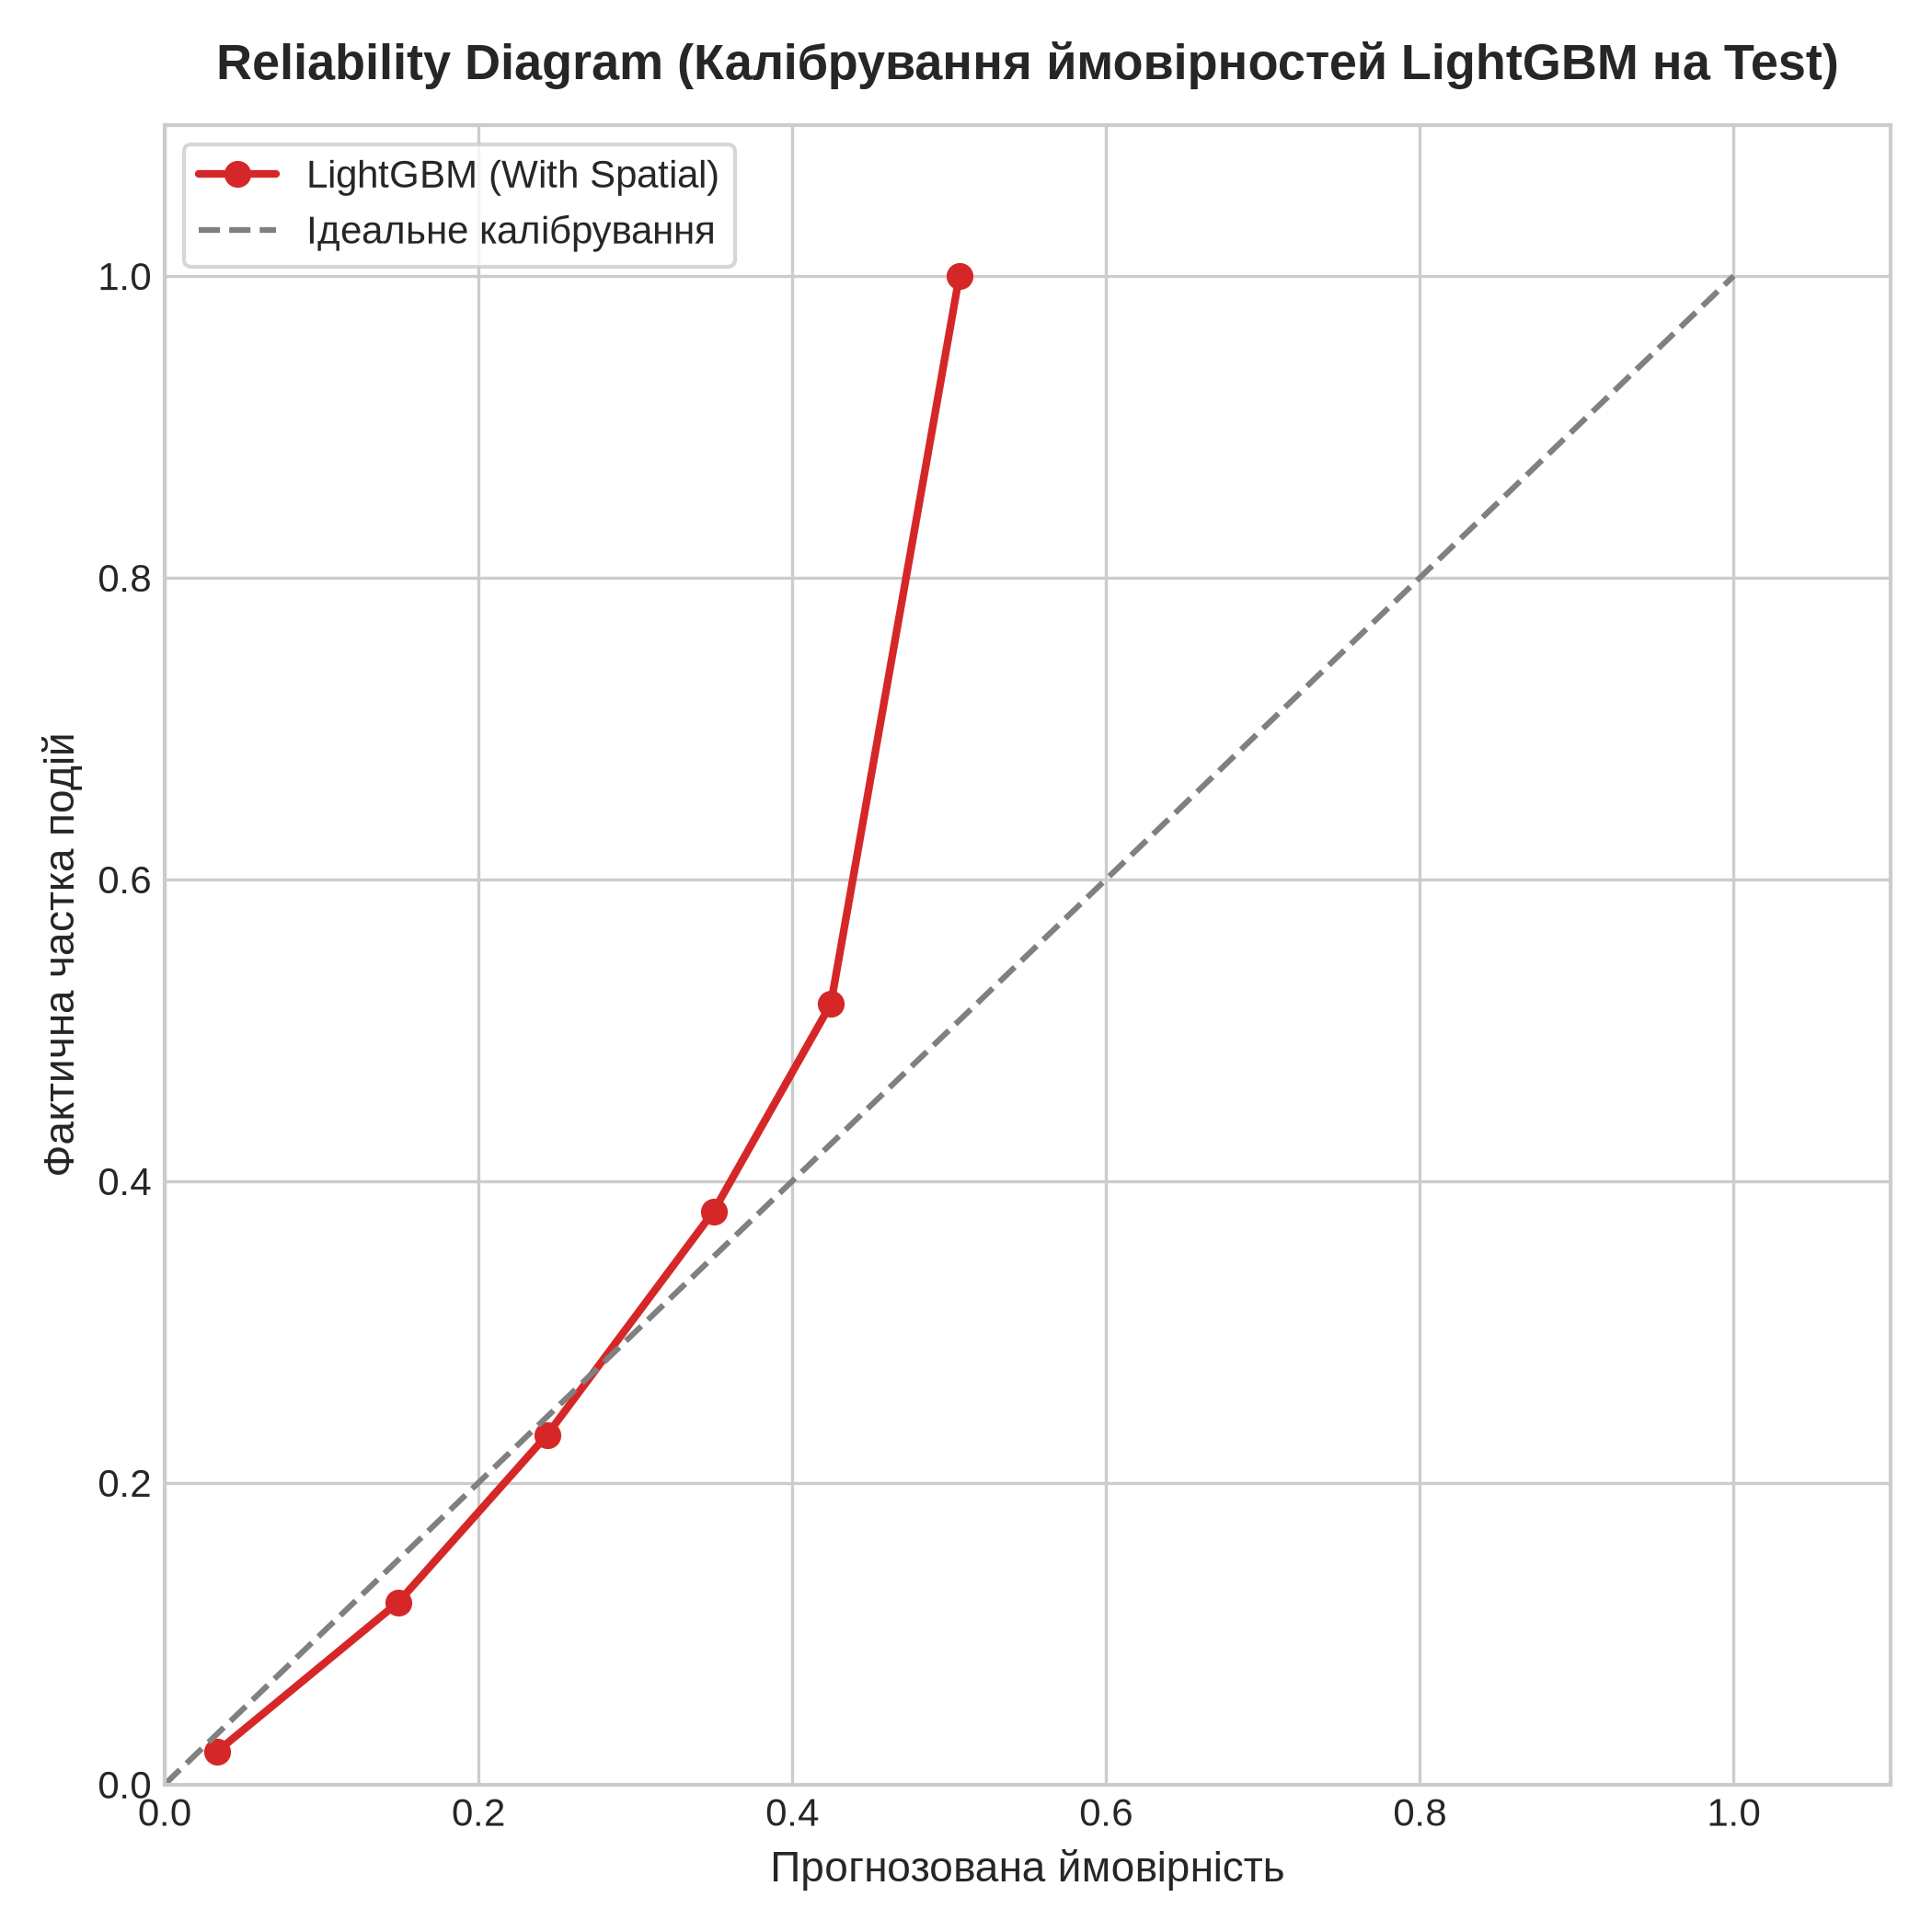

In [5]:
display(Image('../reports/figures/10_test_pr_curves_comparison.png'))
display(Image('../reports/figures/12_lift_over_baselines.png'))
display(Image('../reports/figures/13_calibration_reliability_diagram.png'))

## 4. Важливість ознак (Feature Importance) та методичні обмеження

,feature,feature_ua,gain,split
0,burden_last_24h,Навантаження за 24 год (добовий темп),95668.976718,277
1,cluster_3_high_activity,"Кластер 3 (high_activity, Train)",72662.400994,51
2,neighbors_active_count,Кількість активних сусідів (RQ3),32141.836200,99
3,month,Місяць (сезонність),29217.242610,590
4,hour_sin,Година доби (синус),23705.094168,425
5,hour_cos,Година доби (косинус),20349.840289,356
6,cluster_1_low_activity,"Кластер 1 (low_activity, Train)",17048.567639,56
7,neighbor_active_ratio,Частка активних сусідів (RQ3),16523.607712,123
8,cluster_2_medium_activity,"Кластер 2 (medium_activity, Train)",8905.019361,26
9,day_of_week,День тижня,8596.380347,242


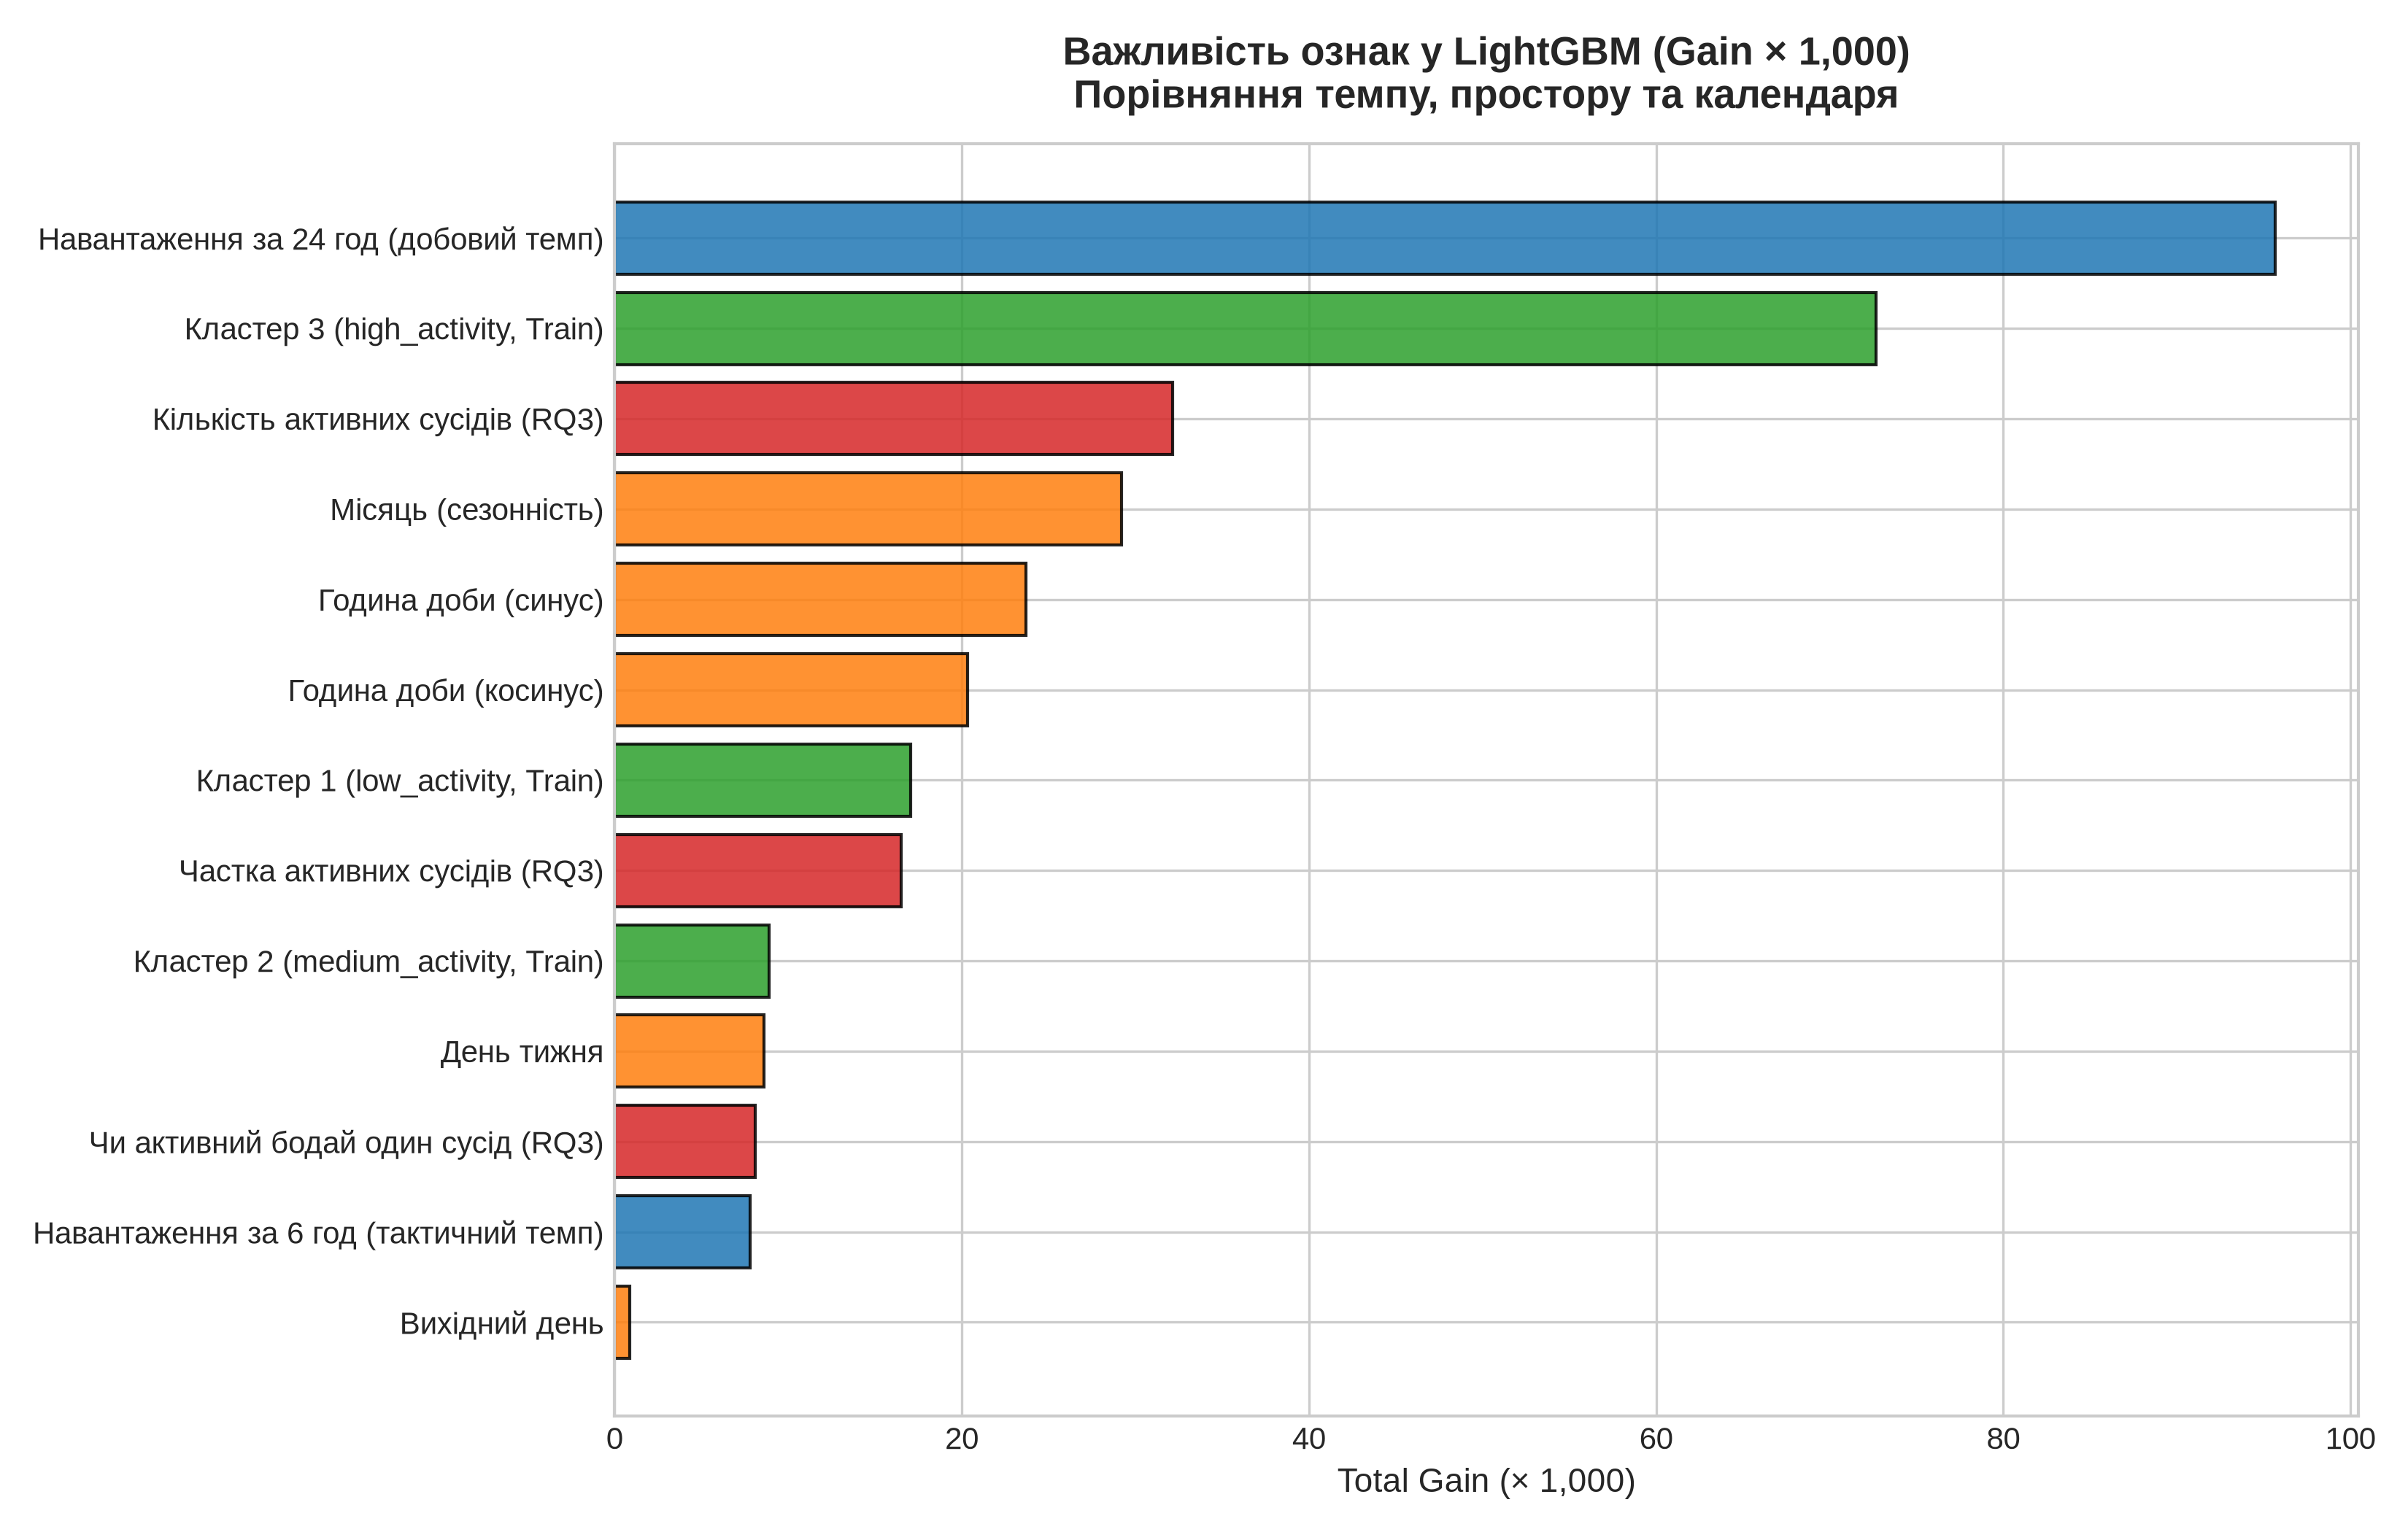

In [6]:
feat_imp = pd.read_csv('../reports/feature_importance_lightgbm.csv')
display(feat_imp)
display(Image('../reports/figures/11_feature_importance_lightgbm.png'))

### Висновки та методичні обмеження:
1. **Вплив просторових ознак:** Парний Day-Block Bootstrap (500 ітерацій за добами) підтверджує статистично значущий приріст PR-AUC для LightGBM при додаванні сусідів: $\Delta \text{PR-AUC} = +0.0259$ (95% CI $[+0.0226, +0.0293]$). Для логістичної регресії різниця PR-AUC статистично незначуща ($\Delta \text{PR-AUC} = +0.0024$, 95% CI $[-0.0017, +0.0065]$).
2. **Порівняння з бейзлайнами:** LightGBM (With Spatial) перевершує найкращий адаптивний бейзлайн на Test як за PR-AUC ($0.3741$ проти $0.3031$, парна різниця $+0.0711$), так і за $F_2$-Score ($0.5597$ проти $0.5299$, парна різниця $+0.0296$). При однаковому Recall ($78.2\%$) точність LightGBM становить $26.8\%$ проти $23.1\%$ у адаптивного бейзлайну. На останніх 60 днях за метрикою $F_2$ адаптивний бейзлайн ($0.6430$) та LightGBM ($0.6429$) працюють на одному рівні, проте за площею під PR-кривою ML-моделі зберігають перевагу (LightGBM PR-AUC $0.4541$ проти $0.3682$).
3. **Обмеження:**
   * Відсіювання мікро-тривог ($<60$ с) у `cleaner.py` спирається на `finished_at`.
   * З серпня 2025 року тривога області визначається як об'єднання інтервалів тривог її районів і громад.
   * Вибірка Validation використовується одночасно для ранньої зупинки (early stopping) у LightGBM та вибору порогу $p^*$.
   * Межі сплітів Train/Val/Test задано у UTC, тоді як добові ознаки розраховано у часовому поясі `Europe/Kyiv`.